# 02 — The joint posterior: one network for all parameters, sampled with MCMC

Notebook 01 learned **marginal** posteriors: one small classifier per group of one or two parameters, and the
posterior of each group came from re-weighting prior samples. Here we use the same toy model (a Gaussian
absorption line on a sloped continuum), the same noise and the same preprocessing, but learn the **joint**
posterior of all four parameters with a single group:

    r(x, θ) = p(depth, centre, width, slope | x) / p(depth, centre, width, slope)

The network trains exactly as before. What changes is how we turn the ratio into posterior samples:

1. train the joint network,
2. compute the posterior by re-weighting prior samples, as in notebook 01, and see why this breaks down,
3. sample the joint posterior with **MCMC** instead,
4. compare both on one corner plot,
5. discuss when the sampling step is needed, and when the marginals of notebook 01 get away without it.

In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():  # Running from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from sbi_nre import *
from sbi_nre.network import group_name
from sbi_nre.toy import PRIOR, simulate_toy

DEVICE = ('cuda' if torch.cuda.is_available()          # NVIDIA GPU
          else 'mps' if torch.backends.mps.is_available()  # Apple silicon GPU
          else 'cpu')
print('Device:', DEVICE)

Device: cuda


## 1. Grid, split, noise and preprocessing (as in notebook 01)

We reuse the toy grid written by notebook 01 (or simulate it if it is not there yet), the same split, and the
same augmentation (Gaussian noise with a log-uniform σ between 0.005 and 0.05) and preprocessing (min-max
normalisation). The noise level σ is again given to the network as context.

In [2]:
GRID_FILE = ROOT / 'data' / 'toy_grid.pt'
if not GRID_FILE.is_file():
    save_grid(simulate_toy(50_000), GRID_FILE)
grid = load_grid(GRID_FILE)
training, validation, test = split(grid, (0.8, 0.1, 0.1), seed=0)

AUGMENT = [step('add_noise', key='signal', out='obs', sigma_key='sigma', sigma_range=[0.005, 0.05])]
PREPROCESS = [step('normalise_minmax', key='obs')]
OBSERVATION = ['obs_norm', 'obs_min', 'obs_max']
CONTEXT = ['sigma']
PARAMS = tuple(PRIOR)  # ('depth', 'centre', 'width', 'slope')
example = apply(PREPROCESS, apply(AUGMENT, select(training, slice(0, 3))))
print('training', n_samples(training), '| validation', n_samples(validation), '| test', n_samples(test))

training 40000 | validation 5000 | test 5000


## 2. One group with all parameters: the joint network

The only change from notebook 01 is the list of parameter groups: a single group containing all four
parameters. The network has the same shape (an embedding of the spectrum and σ, then one classifier), and
`train` is called the same way.

The joint classifier has a harder job than a 2D one (it must judge all four parameters at once), so we let it train
longer (up to 150 epochs; it stops early once the validation loss no longer improves).

epoch   1  train 0.5441  validation 0.1698  *best  (0.8 s)


epoch   2  train 0.1338  validation 0.1493  *best  (0.6 s)


epoch   3  train 0.1009  validation 0.0980  *best  (0.7 s)


epoch   4  train 0.0906  validation 0.1684  (0.6 s)


epoch   5  train 0.0825  validation 0.0886  *best  (0.6 s)


epoch   6  train 0.0802  validation 0.0852  *best  (0.6 s)


... (79 outputs left out)

epoch  86  train 0.0327  validation 0.0343  (0.6 s)


epoch  87  train 0.0314  validation 0.0343  (0.6 s)


epoch  88  train 0.0323  validation 0.0342  (0.7 s)


Stopping: no improvement for 15 epochs.


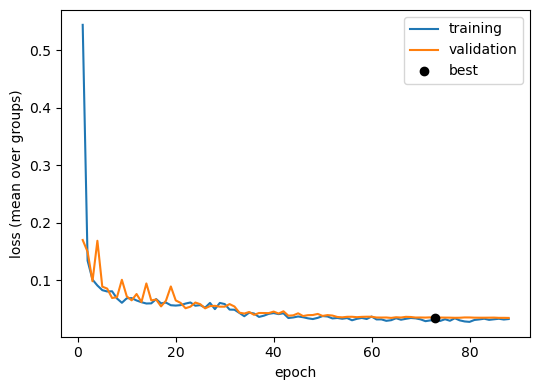

In [3]:
PARAM_GROUPS = [PARAMS]
model = build_model(example, PARAM_GROUPS, OBSERVATION, CONTEXT, summary_size=64, hidden=[256, 256])

RUN_DIR = ROOT / 'runs' / time.strftime('toy_joint_%Y%m%d_%H%M%S')
history = train(model, training, validation, RUN_DIR, augment=AUGMENT, preprocess=PREPROCESS,
                batch_size=256, learning_rate=1e-3, max_epochs=150, patience=15, device=DEVICE,
                notes='Toy model, joint posterior of all four parameters')
plot_history(history, groups=False);

## 3. The posterior without MCMC: re-weighting prior samples

We take the same test spectrum as in notebook 01 and do exactly what notebook 01 did: draw 200,000 samples
from the prior, weight each by r(x, θ), and treat the weighted samples as the posterior. Watch the
**effective sample size** (ESS): how many equally weighted samples the weighted set is worth.

We look at two observations of the same absorption line:

* **A**: the noisy spectrum of notebook 01 (σ ≈ 0.04, near the noisy end of the training range);
* **B**: the same line observed with the least noise of the training range (σ = 0.005), i.e. better data.

true parameters: {'depth': 0.1787, 'centre': 0.1408, 'width': 0.0783, 'slope': -0.1064}
A (σ = 0.040): ESS of the re-weighted joint posterior   142.3 out of 200,000 prior samples
B (σ = 0.005): ESS of the re-weighted joint posterior    27.7 out of 200,000 prior samples


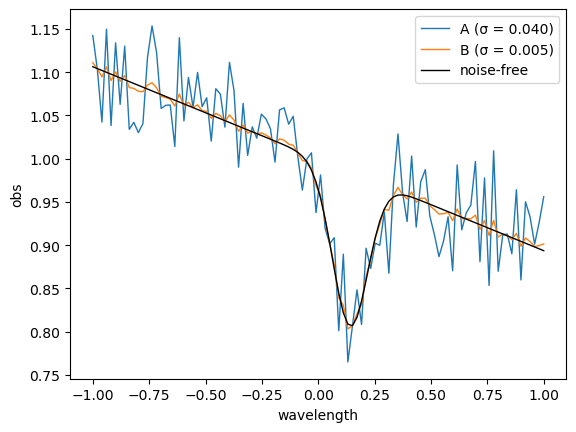

In [4]:
run = load_run(RUN_DIR, device=DEVICE)
GROUP = group_name(PARAMS)

torch.manual_seed(30)
observation_a = select(apply(AUGMENT, select(test, slice(0, 1))), 0)  # The same noisy test spectrum as notebook 01.
torch.manual_seed(30)
LOW_NOISE = [step('add_noise', key='signal', out='obs', sigma_key='sigma', sigma_range=[0.005, 0.005])]
observation_b = select(apply(LOW_NOISE, select(test, slice(0, 1))), 0)  # Same line, σ = 0.005.
observations = {'A (σ = %.3f)' % float(observation_a['sigma']): observation_a,
                'B (σ = %.3f)' % float(observation_b['sigma']): observation_b}
truths = {p: float(observation_a[p]) for p in PARAMS}
print('true parameters:', {p: round(v, 4) for p, v in truths.items()})

x = torch.linspace(-1, 1, observation_a['obs'].shape[-1])
for label, obs in observations.items():
    plt.plot(x, obs['obs'], lw=1, label=label)
plt.plot(x, observation_a['signal'], 'k', lw=1, label='noise-free')
plt.xlabel('wavelength'); plt.ylabel('obs'); plt.legend();

prior_samples = uniform_prior_samples(PRIOR, 200_000)
reweighted = {}
for label, obs in observations.items():
    reweighted[label] = posterior(run, obs, prior_samples, min_ess=None)[GROUP]
    print(f'{label}: ESS of the re-weighted joint posterior {effective_sample_size(reweighted[label]["weights"]):7.1f} '
          'out of 200,000 prior samples')

Of 200,000 prior samples, only about a hundred effective samples remain for **A**, and a few tens for **B**:
better data make the posterior narrower, so even fewer prior samples land in it. (The exact numbers change a
little every time the network is retrained.) Compare notebook 01, where every 1D or 2D group kept thousands.
More prior samples help only slowly: the ESS grows in proportion to their number, so ten times the ESS costs ten
times the prior samples and ten times the network evaluations:

In [5]:
for n in (20_000, 200_000, 2_000_000):
    samples = uniform_prior_samples(PRIOR, n, seed=1)
    ess = [effective_sample_size(posterior(run, obs, samples, min_ess=None)[GROUP]['weights']) for obs in observations.values()]
    print(f'{n:>9,} prior samples -> ESS  A: {ess[0]:8.1f}   B: {ess[1]:8.1f}')

   20,000 prior samples -> ESS  A:     18.6   B:      5.0
  200,000 prior samples -> ESS  A:    149.9   B:     27.8


2,000,000 prior samples -> ESS  A:   1393.3   B:    262.6


**Why?** Re-weighting only works if enough prior samples land where the posterior is. If the posterior is a
fraction *f* of the prior's width in each parameter, the fraction of prior samples that land inside it is
roughly *f* per dimension, multiplied over all dimensions:

| posterior width / prior width | 1D | 2D | 4D (this notebook) | 14D (a retrieval) |
|---|---|---|---|---|
| f = 0.2 | 1 in 5 | 1 in 25 | 1 in 625 | 1 in 6 × 10⁹ |
| f = 0.05 | 1 in 20 | 1 in 400 | 1 in 160,000 | 1 in 6 × 10¹⁸ |

So with 200,000 prior samples a 1D or 2D posterior is resolved by hundreds to thousands of samples, while a
joint posterior over many parameters gets a few, or none. This is the "curse of dimensionality" of importance
sampling with the prior as the proposal. Section 5 measures *f* for both observations.

## 4. Sampling the joint posterior with MCMC

Instead of hoping that prior samples land in the posterior, **Markov chain Monte Carlo** walks to it and
stays there. It only needs the (unnormalised) log posterior density at any θ:

    log p(θ | x) = log r(x, θ) + log p(θ) + const

and the network gives log r(x, θ) for any θ in microseconds. Our prior is uniform, so log p(θ) is constant
inside the prior box and −∞ outside it.

We use the **affine-invariant ensemble sampler** (Goodman & Weare 2010, the algorithm of `emcee`): many
walkers move together, each proposing a step along the line to another walker. It needs no tuning of step
sizes and copes well with correlated parameters. Here it is written in a few lines of PyTorch so that all
walkers are evaluated by the network in one batch on the GPU.

* **Walkers** start at the best of the re-weighted prior samples, already close to the posterior.
* **Burn-in**: the first steps, while the walkers spread out over the posterior, are discarded.
* **Thinning**: neighbouring steps of a chain are correlated, so we keep only every 10th step.
* **Acceptance fraction**: the fraction of proposed steps that are taken; for this sampler in a few
  dimensions about 0.2–0.6 is typical. Close to 0 means the walkers are stuck.

In [6]:
@torch.no_grad()
def log_posterior(run, summary, theta, prior):
    '''log r(x, θ) + log prior (uniform: 0 inside the box, -inf outside), for a batch θ [n, n_params].'''
    low = torch.tensor([prior[p][0] for p in PARAMS], device=theta.device)
    high = torch.tensor([prior[p][1] for p in PARAMS], device=theta.device)
    inside = ((theta >= low) & (theta <= high)).all(1)
    params = {p: theta[:, i] for i, p in enumerate(PARAMS)}
    log_r = run.model.log_ratio(summary.expand(len(theta), -1), params, PARAMS)
    return torch.where(inside, log_r, torch.tensor(-torch.inf, device=theta.device))


@torch.no_grad()
def ensemble_mcmc(run, observation, prior, start, n_steps=3000, a=2.0, seed=0):
    '''Affine-invariant 'stretch move' ensemble sampler (Goodman & Weare 2010), all walkers in one batch.

    start: [n_walkers, n_params] initial positions. Returns the chain [n_steps, n_walkers, n_params]
    and the acceptance fraction.
    '''
    generator = torch.Generator(device=start.device).manual_seed(seed)
    model = run.model.eval()
    summary = model.summary(apply(run.preprocess, {k: torch.as_tensor(v, device=start.device).float()[None]
                                                   for k, v in observation.items()}))
    walkers = start.clone()
    log_p = log_posterior(run, summary, walkers, prior)
    n, d = walkers.shape
    half = n // 2
    chain, accepted = [], 0
    for _ in range(n_steps):
        for active, partner in ((slice(0, half), slice(half, n)), (slice(half, n), slice(0, half))):
            x, others = walkers[active], walkers[partner]
            k = len(x)
            z = ((a - 1) * torch.rand(k, device=x.device, generator=generator) + 1) ** 2 / a  # g(z) ∝ 1/√z on [1/a, a]
            pick = others[torch.randint(len(others), (k,), device=x.device, generator=generator)]
            proposal = pick + z[:, None] * (x - pick)
            log_p_new = log_posterior(run, summary, proposal, prior)
            log_accept = (d - 1) * torch.log(z) + log_p_new - log_p[active]
            accept = torch.log(torch.rand(k, device=x.device, generator=generator)) < log_accept
            walkers[active] = torch.where(accept[:, None], proposal, x)
            log_p[active] = torch.where(accept, log_p_new, log_p[active])
            accepted += int(accept.sum())
        chain.append(walkers.clone())
    return torch.stack(chain), accepted / (n_steps * n)


def start_walkers(weighted, n_walkers, prior):
    '''Start positions: the best re-weighted prior samples, spread out a little and kept inside the prior.'''
    pick = torch.multinomial(weighted['weights'], n_walkers, replacement=True)
    start = torch.stack([weighted['samples'][p][pick] for p in PARAMS], 1)
    low = start.new_tensor([prior[p][0] for p in PARAMS])
    high = start.new_tensor([prior[p][1] for p in PARAMS])
    start = start + 1e-3 * (high - low) * torch.randn_like(start)
    return torch.max(torch.min(start, high), low)


N_WALKERS, N_STEPS, BURN_IN, THIN = 64, 3000, 1000, 10
chains, mcmc = {}, {}
for label, obs in observations.items():
    t0 = time.time()
    chains[label], acceptance = ensemble_mcmc(run, obs, PRIOR, start_walkers(reweighted[label], N_WALKERS, PRIOR),
                                              n_steps=N_STEPS)
    kept = chains[label][BURN_IN::THIN].reshape(-1, len(PARAMS))  # equal-weight posterior samples
    mcmc[label] = {p: kept[:, i] for i, p in enumerate(PARAMS)}
    print(f'{label}: {N_WALKERS} walkers x {N_STEPS} steps in {time.time() - t0:.1f} s, '
          f'acceptance fraction {acceptance:.2f}, {len(kept):,} samples kept')

A (σ = 0.040): 64 walkers x 3000 steps in 7.7 s, acceptance fraction 0.55, 12,800 samples kept


B (σ = 0.005): 64 walkers x 3000 steps in 7.6 s, acceptance fraction 0.57, 12,800 samples kept


**Check the chains** (observation B). After the burn-in (dotted line) the walkers should fluctuate around a
stable region, without trends. The dashed line is the true value.

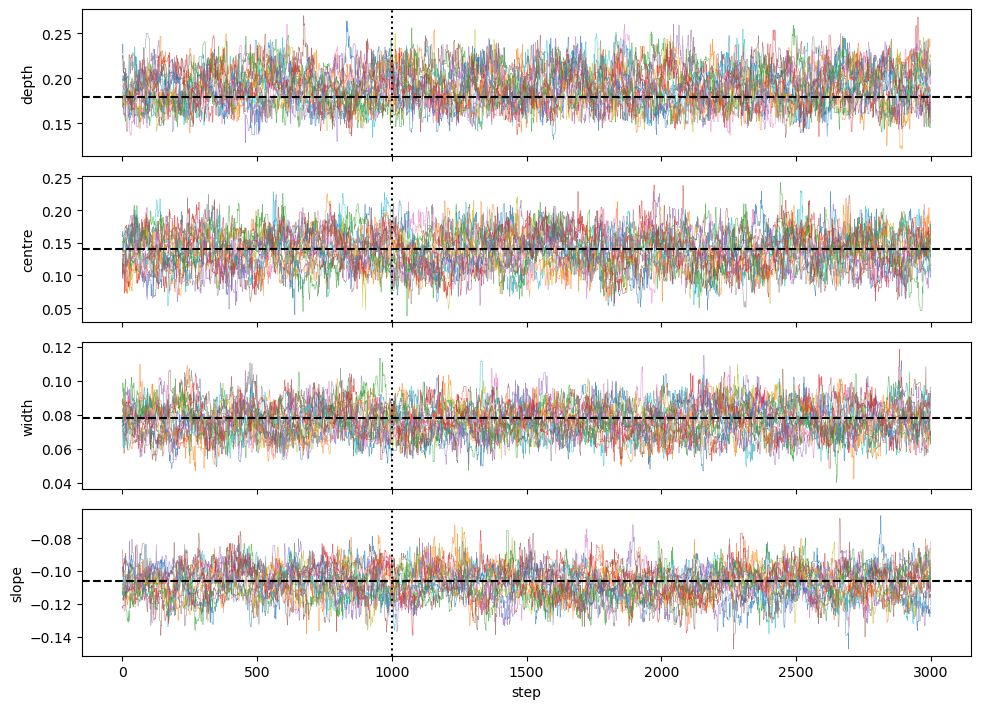

In [7]:
label_b = list(observations)[1]
fig, axes = plt.subplots(len(PARAMS), 1, figsize=(10, 1.8 * len(PARAMS)), sharex=True)
for i, (ax, p) in enumerate(zip(axes, PARAMS)):
    ax.plot(chains[label_b][:, :16, i].cpu().numpy(), lw=.4, alpha=.7)
    ax.axvline(BURN_IN, color='k', ls=':')
    ax.axhline(truths[p], color='k', ls='--')
    ax.set_ylabel(p)
axes[-1].set_xlabel('step')
fig.tight_layout()

## 5. With and without MCMC on one corner plot

Both colours show the posterior of the **same network** for the **same spectrum**; only the way of drawing
samples differs:

* **red**: re-weighted prior samples (no MCMC), as in notebook 01;
* **blue**: MCMC samples.

Contours enclose 68% and 95% of the posterior; the dashed lines mark the true parameters.

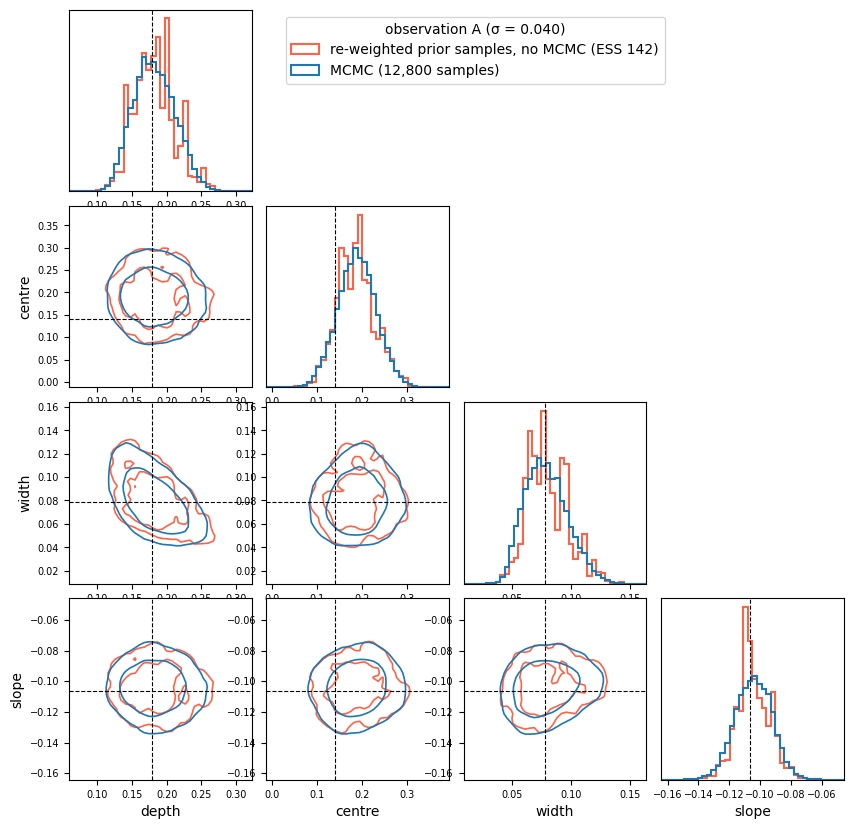

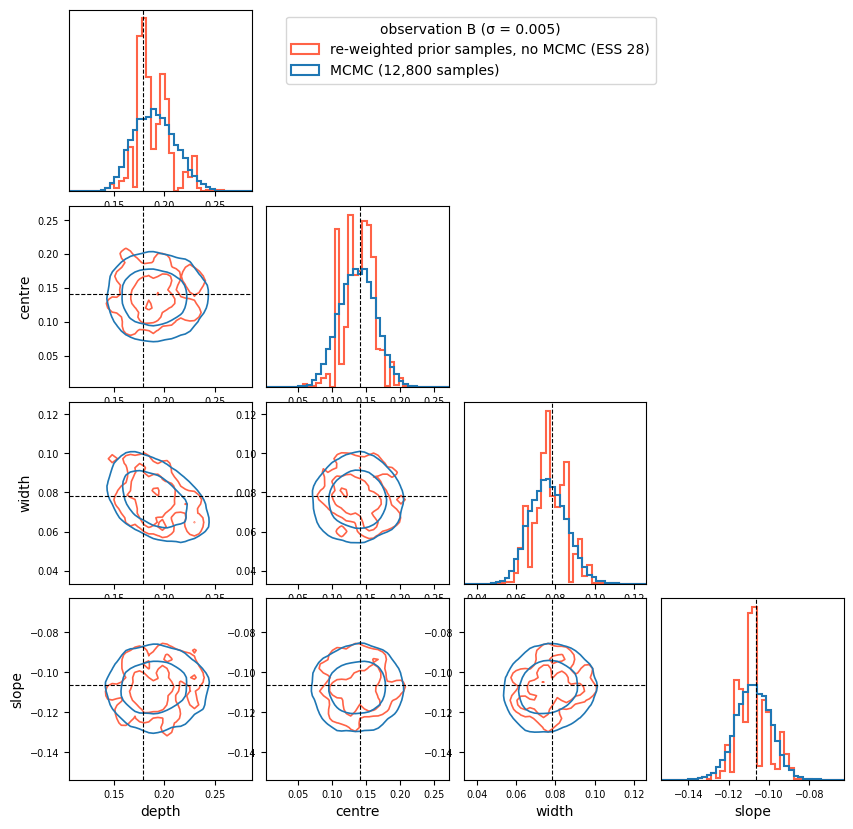

In [8]:
def _smooth(h, sigma=1.0):
    '''Gaussian smoothing of a 2D histogram (numpy only).'''
    r = np.arange(-3, 4)
    kernel = np.exp(-0.5 * (r / sigma) ** 2); kernel /= kernel.sum()
    h = np.apply_along_axis(lambda v: np.convolve(v, kernel, mode='same'), 0, h)
    return np.apply_along_axis(lambda v: np.convolve(v, kernel, mode='same'), 1, h)


def corner(sources, truths, params, zoom_on, bins=40, title=''):
    '''Corner plot with 68% / 95% contours; sources: {label: (samples {p: tensor}, weights or None, colour)}.'''
    n = len(params)
    ranges = {}
    for p in params:  # zoom on one posterior (+ the truth)
        low, high = np.quantile(zoom_on[p].cpu().numpy(), [0.001, 0.999])
        low, high = min(low, truths[p]), max(high, truths[p])
        ranges[p] = (low - 0.3 * (high - low), high + 0.3 * (high - low))
    fig, axes = plt.subplots(n, n, figsize=(2.5 * n, 2.5 * n))
    for i, py in enumerate(params):
        for j, px in enumerate(params):
            ax = axes[i, j]
            if j > i:
                ax.axis('off'); continue
            for label, (samples, weights, colour) in sources.items():
                w = None if weights is None else weights.cpu().numpy()
                x = samples[px].cpu().numpy()
                if i == j:
                    ax.hist(x, bins=bins, range=ranges[px], weights=w, density=True, histtype='step',
                            color=colour, lw=1.5, label=label)
                    continue
                h, xe, ye = np.histogram2d(x, samples[py].cpu().numpy(), bins=bins, weights=w,
                                           range=[ranges[px], ranges[py]])
                h = _smooth(h)
                flat = np.sort(h.ravel())[::-1]
                if flat.sum() == 0:
                    continue
                cumulative = np.cumsum(flat) / flat.sum()
                levels = sorted({flat[min(np.searchsorted(cumulative, m), len(flat) - 1)] for m in (0.95, 0.68)})
                ax.contour((xe[1:] + xe[:-1]) / 2, (ye[1:] + ye[:-1]) / 2, h.T, levels=levels + [h.max() * 1.0001],
                           colors=colour, linewidths=1.2)
            ax.axvline(truths[px], color='k', lw=.8, ls='--')
            if i != j:
                ax.axhline(truths[py], color='k', lw=.8, ls='--')
                ax.set_ylim(ranges[py])
            ax.set_xlim(ranges[px])
            ax.tick_params(labelsize=7)
            if i == n - 1: ax.set_xlabel(px)
            if j == 0 and i != j: ax.set_ylabel(py)
            if i == j: ax.set_yticks([])
    axes[0, 0].legend(loc='upper left', bbox_to_anchor=(1.15, 1), fontsize=10, title=title)
    fig.subplots_adjust(wspace=.08, hspace=.08)
    return fig


for label in observations:
    ess = effective_sample_size(reweighted[label]['weights'])
    corner({f're-weighted prior samples, no MCMC (ESS {ess:.0f})':
                (reweighted[label]['samples'], reweighted[label]['weights'], 'tomato'),
            f'MCMC ({len(mcmc[label][PARAMS[0]]):,} samples)': (mcmc[label], None, 'C0')},
           truths, PARAMS, zoom_on=mcmc[label], title=f'observation {label}');

* Both methods agree on where the posterior is: the network is the same.
* The re-weighted posterior is built from about a hundred (A) or a few tens (B) of effective samples: its 1D
  histograms are spiky and its contours jagged, so widths, tails and correlations are uncertain, and quantiles
  (e.g. a 95% interval) are unreliable. The fewer the effective samples, the worse (B).
* The MCMC posterior is smooth, with ~13,000 samples for the same cost of a few seconds, and shows the shape of
  the joint posterior, e.g. the anti-correlation of depth and width.

With four parameters the re-weighting still gives a rough picture. With more parameters it does not (next
cell and section 6).

How wide are the posteriors compared with the prior? This is the fraction *f* from the table in section 3:

In [9]:
for label in observations:
    f_total = 1.0
    print(f'observation {label}')
    for p in PARAMS:
        low, median, high = np.quantile(mcmc[label][p].cpu().numpy(), [0.16, 0.5, 0.84])
        f = (high - low) / (PRIOR[p][1] - PRIOR[p][0])
        f_total *= f
        print(f'  {p:>7}: {median:8.4f} (+{high - median:.4f} / -{median - low:.4f})   true {truths[p]:8.4f}   '
              f'68% width / prior width f = {f:.3f}')
    print(f'  product of the f: {f_total:.1e} -> about 1 prior sample in {1 / f_total:,.0f} lands in the 68% region\n')

observation A (σ = 0.040)
    depth:   0.1812 (+0.0321 / -0.0291)   true   0.1787   68% width / prior width f = 0.136
   centre:   0.1892 (+0.0421 / -0.0425)   true   0.1408   68% width / prior width f = 0.070
    width:   0.0781 (+0.0194 / -0.0170)   true   0.0783   68% width / prior width f = 0.214
    slope:  -0.1042 (+0.0117 / -0.0119)   true  -0.1064   68% width / prior width f = 0.039
  product of the f: 8.1e-05 -> about 1 prior sample in 12,333 lands in the 68% region

observation B (σ = 0.005)
    depth:   0.1899 (+0.0222 / -0.0205)   true   0.1787   68% width / prior width f = 0.095
   centre:   0.1370 (+0.0270 / -0.0276)   true   0.1408   68% width / prior width f = 0.045
    width:   0.0762 (+0.0097 / -0.0092)   true   0.0783   68% width / prior width f = 0.111
    slope:  -0.1078 (+0.0087 / -0.0085)   true  -0.1064   68% width / prior width f = 0.029
  product of the f: 1.4e-05 -> about 1 prior sample in 72,797 lands in the 68% region



## 6. Why the marginals of notebook 01 could skip this step, and when MCMC is necessary

**Marginal groups (notebook 01).** Each group there covers one or two parameters, and its network learns the
*marginal* ratio p(θ_group | x) / p(θ_group) directly: the other parameters are integrated out by the
training itself (mismatched pairs swap only the group's parameters, and the classifier never sees the others).
A 1D or 2D posterior occupies a fraction of about f or f² of its prior, so 200,000 prior samples leave hundreds
to thousands of them inside it, even for good data. Re-weighting is then cheap, needs no tuning and no
convergence checks, and the ESS tells you when it fails.

**The joint group (this notebook).** The posterior now lives in all dimensions at once, a fraction of roughly
f⁴ of the prior here (f¹⁴ for a 14-parameter retrieval). With four parameters re-weighting still scrapes by with
tens to a hundred effective samples; every additional parameter divides that by another factor of 1/f, so for a
retrieval with 10-15 parameters it returns one or two effective samples, and no affordable number of prior
samples fixes that. The network is fine; the *sampling* fails. MCMC fixes
this by proposing new points near the posterior instead of from the prior.

**When is MCMC necessary?**

* **Joint (or any high-dimensional) groups: in practice always.** Check the ESS of the re-weighting: if it is
  below a few hundred, sample with MCMC. With many parameters it will be.
* **1D and 2D groups: no.** Re-weighting is simpler and exact up to sampling noise.
* **What MCMC adds:** the full joint posterior, so every correlation between every pair of parameters, and
  equally weighted samples that can be pushed through the simulator (posterior predictive spectra) or used for
  quantities that depend on several parameters at once. Marginal groups give only the groups you trained, and
  their 2D panels are not guaranteed to come from one consistent joint distribution.
* **What it costs:** a few seconds per observation instead of a fraction of a second, and checks that the
  chains have converged (burn-in, acceptance fraction, trace plots; for real use also the autocorrelation
  time). The network itself stays amortised: it is trained once and works for every observation.

**In short:** marginal NRE learns low-dimensional posteriors that are easy to read out by re-weighting prior
samples; joint NRE learns the full posterior in one network but needs a sampler to read it out.